In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.preprocessing import MinMaxScaler

RANDOM_STATE = 42

In [2]:
# Gesamtdatensatz erzeugen
X, y = make_moons(n_samples=1000, noise=0.20, random_state=RANDOM_STATE)

# In Trainingspool und Testdaten aufteilen
X_pool, X_test, y_pool, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

# Für alle Strategien denselben initialen gelabelten Datensatz verwenden
rng = np.random.default_rng(RANDOM_STATE)
initial_labeled = []
for cls in np.unique(y_pool):
    class_idx = np.where(y_pool == cls)[0]
    initial_labeled.extend(rng.choice(class_idx, size=5, replace=False))

initial_labeled = np.array(initial_labeled, dtype=int)

print("Pool:", X_pool.shape)
print("Test:", X_test.shape)
print("Initial gelabelt:", len(initial_labeled))
print("Klassen im initialen Set:", np.bincount(y_pool[initial_labeled]))

Pool: (750, 2)
Test: (250, 2)
Initial gelabelt: 10
Klassen im initialen Set: [5 5]


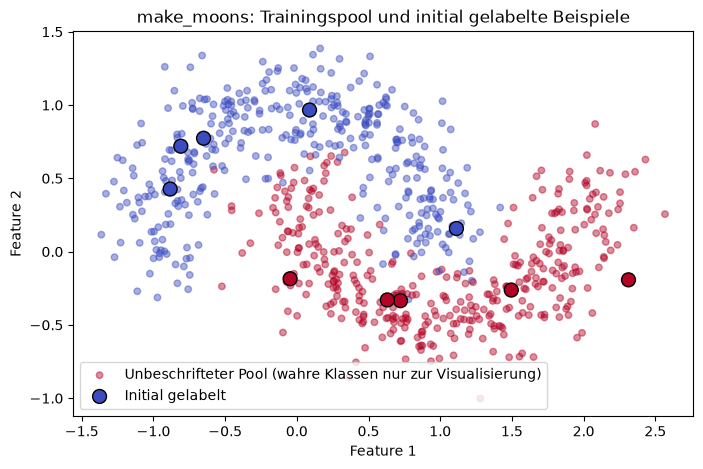

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(X_pool[:, 0], X_pool[:, 1], c=y_pool, cmap="coolwarm",
            s=22, alpha=0.45, label="Unbeschrifteter Pool (wahre Klassen nur zur Visualisierung)")
plt.scatter(X_pool[initial_labeled, 0], X_pool[initial_labeled, 1],
            c=y_pool[initial_labeled], cmap="coolwarm",
            edgecolor="black", s=100, marker="o", label="Initial gelabelt")
plt.title("make_moons: Trainingspool und initial gelabelte Beispiele")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

Unsicherheit (Margin) und Klassifikator

In [4]:
def train_classifier(X_labeled, y_labeled):
    # probability=True liefert Wahrscheinlichkeiten für BvSB
    model = SVC(kernel="rbf", C=2.0, gamma="scale",
                probability=True, random_state=RANDOM_STATE)
    model.fit(X_labeled, y_labeled)
    return model


def uncertainty_bvsb(model, X_unlabeled):
    probs = model.predict_proba(X_unlabeled)
    # Differenz zwischen den zwei höchsten Klassenwahrscheinlichkeiten
    sorted_probs = np.sort(probs, axis=1)
    margin = sorted_probs[:, -1] - sorted_probs[:, -2]
    return 1.0 - margin

Representativeness

In [5]:
def representativeness_gp(X_unlabeled, gamma=None, jitter=1e-6):
    n = len(X_unlabeled)
    if n < 2:
        return np.ones(n)

    # RBF-Kernel als GP-Kovarianzmatrix
    if gamma is None:
        gamma = 1.0 / X_unlabeled.shape[1]
    K = rbf_kernel(X_unlabeled, X_unlabeled, gamma=gamma)
    K = K + jitter * np.eye(n)

    # Diagonale von K^{-1}; solve ist numerisch günstiger als explizite inverse()
    K_inv = np.linalg.solve(K, np.eye(n))
    conditional_var = 1.0 / np.maximum(np.diag(K_inv), 1e-12)
    marginal_var = np.diag(K)

    rep = 0.5 * np.log(
        np.maximum(marginal_var, 1e-12) /
        np.maximum(conditional_var, 1e-12)
    )

    # Kleine numerische Rundungsfehler abfangen
    rep = np.maximum(rep, 0.0)
    return rep


def minmax_score(scores):
    scores = np.asarray(scores, dtype=float)
    lo, hi = scores.min(), scores.max()
    if hi - lo < 1e-12:
        return np.ones_like(scores)
    return (scores - lo) / (hi - lo)

Uncertainty + Representativeness

In [6]:
def information_content(uncertainty, representativeness, lam=1.0):
    u = minmax_score(uncertainty)
    r = minmax_score(representativeness)
    return lam * u * r

Diversity mit Kernel k-means

In [7]:
def kernel_kmeans_select(X_candidates, n_clusters, gamma=None,
                         max_iter=50, random_state=42):
    n = len(X_candidates)
    n_clusters = min(n_clusters, n)
    if n_clusters == n:
        return np.arange(n)

    if gamma is None:
        gamma = 1.0 / X_candidates.shape[1]

    K = rbf_kernel(X_candidates, X_candidates, gamma=gamma)
    rng = np.random.default_rng(random_state)

    # Initialisierung: zufällige unterschiedliche Cluster-Zuordnungen
    labels = np.arange(n) % n_clusters
    rng.shuffle(labels)

    for _ in range(max_iter):
        old_labels = labels.copy()
        distances = np.full((n, n_clusters), np.inf)

        for c in range(n_clusters):
            members = np.where(labels == c)[0]
            if len(members) == 0:
                continue

            # Kernel-k-means-Distanz jedes Punktes zu Cluster c
            sum_to_cluster = K[:, members].sum(axis=1)
            within_cluster = K[np.ix_(members, members)].sum()
            m = len(members)

            distances[:, c] = (
                np.diag(K)
                - 2.0 * sum_to_cluster / m
                + within_cluster / (m * m)
            )

        labels = np.argmin(distances, axis=1)

        # Leere Cluster vermeiden: einem leeren Cluster den aktuell
        # am schlechtesten zugeordneten Punkt geben
        for c in range(n_clusters):
            if not np.any(labels == c):
                assigned_dist = distances[np.arange(n), labels]
                move_idx = np.argmax(assigned_dist)
                labels[move_idx] = c

        if np.array_equal(labels, old_labels):
            break

    # Pro Cluster den realen Punkt mit kleinster Kernel-Distanz zum Zentrum wählen
    selected = []
    for c in range(n_clusters):
        members = np.where(labels == c)[0]
        if len(members) == 0:
            continue

        # Distanz der Cluster-Mitglieder zum eigenen Kernel-Zentrum
        subK = K[np.ix_(members, members)]
        m = len(members)
        d2 = (
            np.diag(subK)
            - 2.0 * subK.sum(axis=1) / m
            + subK.sum() / (m * m)
        )
        selected.append(members[np.argmin(d2)])

    return np.array(selected, dtype=int)

wir setzen alles zusammen: 1. nur uncertainty 2.uncertainty_representativeness = wählt nach dem Produkt aus beiden Scores 3. full: nimmt zunächst die Top-Kandidaten nach Information Content und wendet darauf Kernel-k-means an.

In [8]:
def select_batch(model, X_unlabeled, strategy, batch_size=10,
                 candidate_factor=5, gp_max_points=500, random_state=42):
    uncertainty = uncertainty_bvsb(model, X_unlabeled)

    if strategy == "uncertainty":
        return np.argsort(uncertainty)[-batch_size:]

    # Für die GP-Kovarianz ist die Matrixinversion O(n^3).
    # Falls der Pool sehr groß ist, wird für das Lehrbeispiel eine
    # zufällige Teilmenge zur GP-Schätzung verwendet.
    if len(X_unlabeled) > gp_max_points:
        rng = np.random.default_rng(random_state)
        gp_idx = np.sort(rng.choice(len(X_unlabeled), gp_max_points, replace=False))
        rep_subset = representativeness_gp(X_unlabeled[gp_idx])
        rep = np.interp(np.arange(len(X_unlabeled)), gp_idx, rep_subset)
        # Außerhalb der GP-Teilmenge: nächster GP-Stützpunkt als Näherung
        missing = np.setdiff1d(np.arange(len(X_unlabeled)), gp_idx)
        if len(missing):
            nearest = np.argmin(
                ((X_unlabeled[missing, None, :] - X_unlabeled[gp_idx][None, :, :])**2).sum(axis=2),
                axis=1
            )
            rep[missing] = rep_subset[nearest]
    else:
        rep = representativeness_gp(X_unlabeled)

    info = information_content(uncertainty, rep)

    if strategy == "uncertainty_representativeness":
        return np.argsort(info)[-batch_size:]

    if strategy == "full":
        n_candidates = min(len(X_unlabeled), candidate_factor * batch_size)
        candidate_idx = np.argsort(info)[-n_candidates:]
        local_selected = kernel_kmeans_select(
            X_unlabeled[candidate_idx],
            n_clusters=batch_size,
            random_state=random_state
        )
        return candidate_idx[local_selected]

    raise ValueError(f"Unbekannte Strategie: {strategy}")

Active Learning über mehrere Runden
Alle drei Strategien starten mit denselben gelabelten Beispielen und erhalten pro Runde dieselbe Anzahl neuer Labels. Die Testdaten werden während der Auswahl nicht verwendet.

In [9]:
def run_active_learning(strategy, batch_size=10, n_rounds=12):
    labeled_idx = initial_labeled.copy()
    unlabeled_idx = np.setdiff1d(np.arange(len(X_pool)), labeled_idx)

    accuracies = []
    labeled_counts = []

    for round_idx in range(n_rounds + 1):
        model = train_classifier(X_pool[labeled_idx], y_pool[labeled_idx])
        y_pred = model.predict(X_test)

        accuracies.append(accuracy_score(y_test, y_pred))
        labeled_counts.append(len(labeled_idx))

        if round_idx == n_rounds or len(unlabeled_idx) == 0:
            break

        local_batch = select_batch(
            model,
            X_pool[unlabeled_idx],
            strategy=strategy,
            batch_size=min(batch_size, len(unlabeled_idx)),
            random_state=RANDOM_STATE + round_idx
        )

        newly_selected = unlabeled_idx[local_batch]
        labeled_idx = np.concatenate([labeled_idx, newly_selected])
        unlabeled_idx = np.setdiff1d(unlabeled_idx, newly_selected)

    return {
        "strategy": strategy,
        "accuracies": np.array(accuracies),
        "labeled_counts": np.array(labeled_counts),
        "labeled_idx": labeled_idx
    }

In [10]:
strategies = [
    "uncertainty",
    "uncertainty_representativeness",
    "full"
]

results = {}
for strategy in strategies:
    print("Starte:", strategy)
    results[strategy] = run_active_learning(strategy)

print("Fertig.")

Starte: uncertainty
Starte: uncertainty_representativeness
Starte: full
Fertig.


Ergebnisse vergleichen
Wir plotten die Test-Accuracy gegen die Anzahl der gelabelten Trainingsbeispiele. Das ist die zentrale Auswertung: Welche Strategie erreicht mit demselben Label-Budget die beste Leistung?

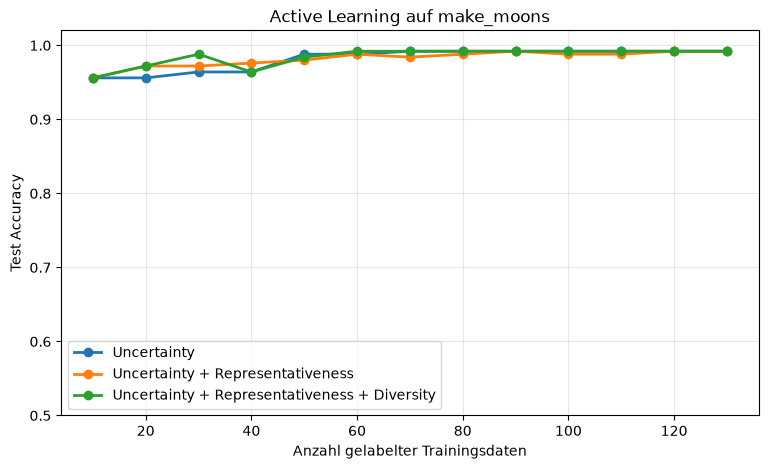

In [11]:
labels = {
    "uncertainty": "Uncertainty",
    "uncertainty_representativeness": "Uncertainty + Representativeness",
    "full": "Uncertainty + Representativeness + Diversity"
}

plt.figure(figsize=(9, 5))
for strategy, result in results.items():
    plt.plot(
        result["labeled_counts"],
        result["accuracies"],
        marker="o",
        linewidth=2,
        label=labels[strategy]
    )

plt.xlabel("Anzahl gelabelter Trainingsdaten")
plt.ylabel("Test Accuracy")
plt.title("Active Learning auf make_moons")
plt.ylim(0.5, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Visualisierung: Hier visualisieren wir die endgültig gelabelten Trainingspunkte einer Strategie. Die Farben zeigen die wahren Klassen (nur zur nachträglichen Analyse); die Auswahl selbst hat diese Labels nicht gesehen.

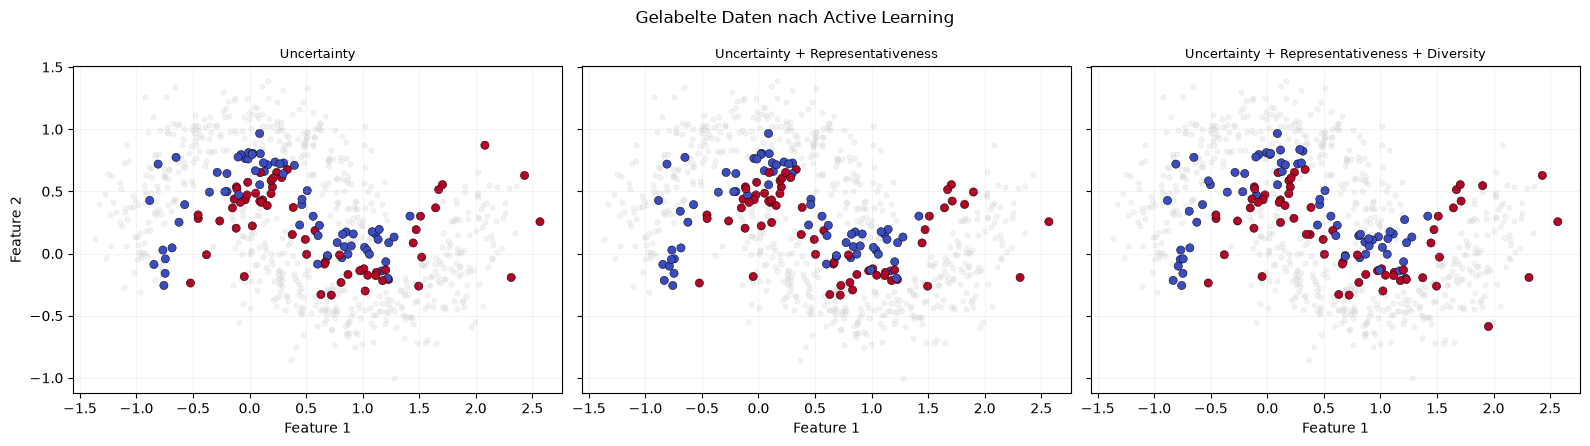

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)

for ax, strategy in zip(axes, strategies):
    idx = results[strategy]["labeled_idx"]
    ax.scatter(X_pool[:, 0], X_pool[:, 1], c="lightgray", s=12, alpha=0.25)
    ax.scatter(
        X_pool[idx, 0], X_pool[idx, 1],
        c=y_pool[idx], cmap="coolwarm",
        edgecolor="black", linewidth=0.35, s=35
    )
    ax.set_title(labels[strategy], fontsize=9)
    ax.set_xlabel("Feature 1")
    ax.grid(alpha=0.15)

axes[0].set_ylabel("Feature 2")
plt.suptitle("Gelabelte Daten nach Active Learning")
plt.tight_layout()
plt.show()